# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: NOMBRE DEL GRUPO

# Integrantes
* integrante
* integrante

In [33]:
import os
import importlib
import numpy as np
import alc
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd

importlib.reload(alc)
np.set_printoptions(precision=4, suppress=True)

# rutas (notebook en la raíz del repo)
PATH_CORNERS = os.path.join("calib", "coplanar", "detected_corners.txt")
N_IMG, N_PTS = 10, 77

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


In [19]:
# proyecciones detectadas: 1 fila por imagen, esquinas intercaladas (u,v)
detected = np.loadtxt(PATH_CORNERS)              # (10, 154)
print("detected:", detected.shape)               # sanity del formato

# puntos del tablero: analíticos, fila-mayor (X=30i, Y=30j, Z=0) en mm
n = np.arange(N_PTS)
objPts = np.column_stack([30.0*(n % 11), 30.0*(n // 11), np.zeros(N_PTS)])
print("objPts[0], objPts[11], objPts[76]:", objPts[0], objPts[11], objPts[76])

X, Y = objPts[:, 0], objPts[:, 1]        # (usadas por el QA de reproyección y los plots

detected: (10, 154)
objPts[0], objPts[11], objPts[76]: [0. 0. 0.] [ 0. 30.  0.] [300. 180.   0.]


### Calibración (Zhang 2000, caso coplanar)

Cada imagen aporta la homografía $H_j$ (solución de mínimos cuadrados
homogéneos, ec. 8) y las restricciones

$$ \mathbf{c}_1^{j\top} B\, \mathbf{c}_2^j = 0, \qquad
   \mathbf{c}_1^{j\top} B\, \mathbf{c}_1^j \;=\; \mathbf{c}_2^{j\top} B\, \mathbf{c}_2^j $$

con $B = K^{-\top}K^{-1}$ simétrica ⇒ 6 incógnitas $\mathbf b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})^\top$.
Armando $A\in\mathbb{R}^{2N\times 6}$ y tomando el **vector nulo** de $A$ (norma 1)
obtenemos $\mathbf b$; el signo se elige de modo que $B$ sea definida positiva,
y $K = (L^\top)^{-1}$ con $B = LL^\top$ (Cholesky), normalizada con $K_{33}=1$.

a) Obtener la matriz $\mathbf{K}$

In [20]:
# 1. Homografía por imagen: DLT coplanar (ec. 11 + ec. 8)
Hlst = []
for k in range(N_IMG):
    imgPts = detected[k].reshape(N_PTS, 2)
    Q  = alc.obtenerQ2d(imgPts, objPts)            # (154, 9)
    H  = alc.resolverDLT2D(Q)                      # (3, 3), ‖h‖=1 
    Hlst.append(H)

# 2. Matriz A de restricciones de Zhang (ec. 13): 2 filas por vista
A = alc.armarA(Hlst)                               # (20, 6)

# 3. K: núcleo de A → b → B def. positiva → Cholesky → K (K33=1)
K = alc.calcularMatrizK2D(A)
print("K:\n", K)

K:
 [[742.3299  -0.6789 520.4803]
 [  0.     753.564  299.2673]
 [  0.       0.       1.    ]]


b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

In [21]:
# Pose (R1, t1) de la cámara respecto del tablero en la captura Im_R_1.png;
# t viaja en mm (λ = 1/‖K⁻¹c₁‖ re-escala la normalización arbitraria del
# vector nulo de la SVD a las unidades de las esquinas del tablero).
# El signo de H es arbitrario: si el DLT devuelve −H, la pose sale como la
# variante alternativa válida (R' = R·diag(−1,−1,1)) — ver markdown de abajo.
Rj1, tj1 = alc.obtenerPose2D(Hlst[0], K)
Rj10, tj10 = alc.obtenerPose2D(Hlst[9], K)
print(f'======== Pose Im_R_1 ======\n Rj1 \n{Rj1}\n tj1\n{tj1}')
print(f'======== Pose Im_R_10 ======\n Rj10 \n{Rj10}\n tj10\n{tj10}')



======== Pose Im_R_1 ======
 Rj1 
[[-0.9995  0.013  -0.0276]
 [-0.0121 -0.9994  0.0078]
 [-0.0275  0.0082  0.9991]]
 tj1
[ 109.2896  141.8554 -548.2162]
======== Pose Im_R_10 ======
 Rj10 
[[-0.9974 -0.0682 -0.025 ]
 [ 0.0632 -0.9856  0.157 ]
 [-0.0353  0.155   0.9874]]
 tj10
[  96.5027  154.4873 -538.9271]


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [36]:
# PENDIENTE (Ej 5a): K PROVISORIA. Consultar el martes cómo calcularla: con el csv tal
# cual da inverosímil, y sus coordenadas no coinciden con las del archivo de 51 puntos.
# K simplificada: gamma = 0, alpha_u = alpha_v = f, centro en el medio de la imagen.
f = 2000.0
K_calle = np.array([[f, 0, 800],
                    [0, f, 600],
                    [0, 0, 1]])

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

In [37]:

#Me traigo los puntos y los guardo en una matriz
GS_Path = os.path.join("salguero", "gs_10_09_point_correspondences_v5.txt")
pts = np.loadtxt(GS_Path)
print(pts.shape)

#Separo en los puntos de los objetos y de la imagen, las guardo en el formato necesario para las funciones
objPts = alc.transponer(pts[1:4])
imgPts = alc.transponer(pts[4:6])
print(objPts.shape, imgPts.shape)

#Busco Q y H
Q = alc.obtenerQ2d(imgPts, objPts)
H = alc.resolverDLT2D(Q)
print(Q.shape, H.shape)

#Armo las coordenadas homogeneas
P = np.vstack((objPts[:, 0], objPts[:, 1], np.ones(objPts.shape[0])))

#Multiplico por H
proy = alc.multiplicar(H, P)

#Divido por la tercera fila para recuperar el valor en pixeles
u_proy = proy[0] / proy[2]
v_proy = proy[1] / proy[2]

(6, 51)
(51, 3) (51, 2)
(102, 9) (3, 3)


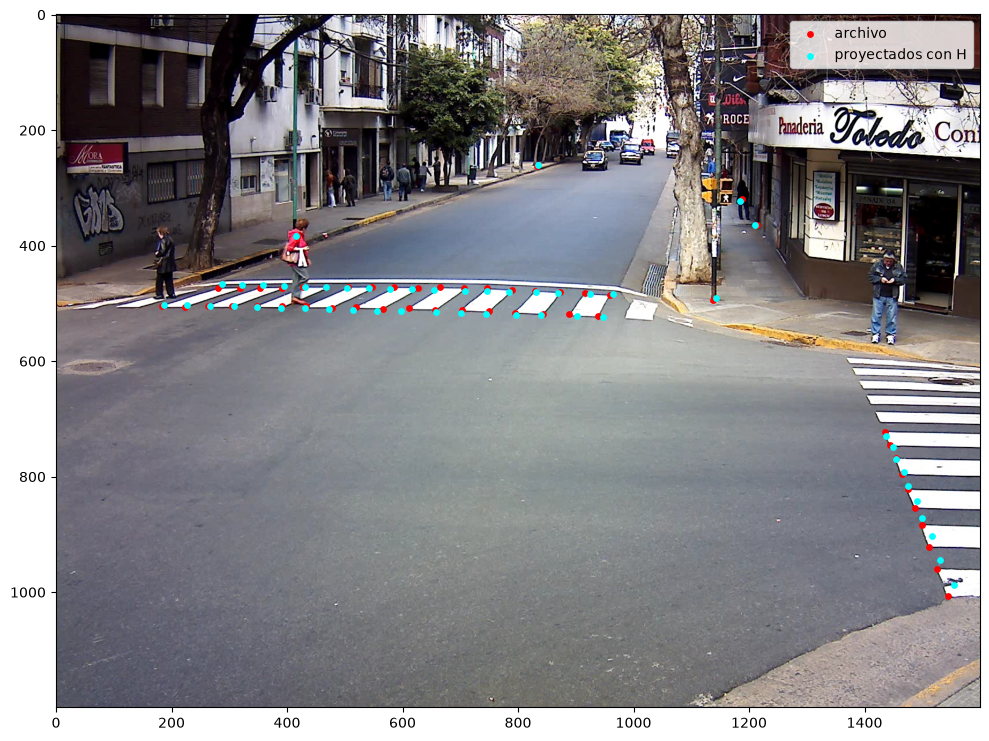

In [31]:
#Proyectamos los puntos sobre la imagen

img = mpimg.imread(os.path.join("salguero", "img_10_18_47_351.jpg"))

plt.figure(figsize=(12, 9))
plt.imshow(img)
plt.scatter(imgPts[:, 0], imgPts[:, 1], c="red", s=15, label="archivo")
plt.scatter(u_proy, v_proy, c="cyan", s=15, label="proyectados con H")
plt.legend()
plt.show()

#De paso calculo el error, BORRAR DESPUES
#error = np.sqrt((u_proy - imgPts[:, 0])**2 + (v_proy - imgPts[:, 1])**2)
#print(np.mean(error), np.max(error))

R:
 [[ 0.9874  0.1439  0.002 ]
 [ 0.0343 -0.2016 -0.9772]
 [-0.1546  0.9672 -0.204 ]]
t: [-3.2982 -1.0238 23.0456]


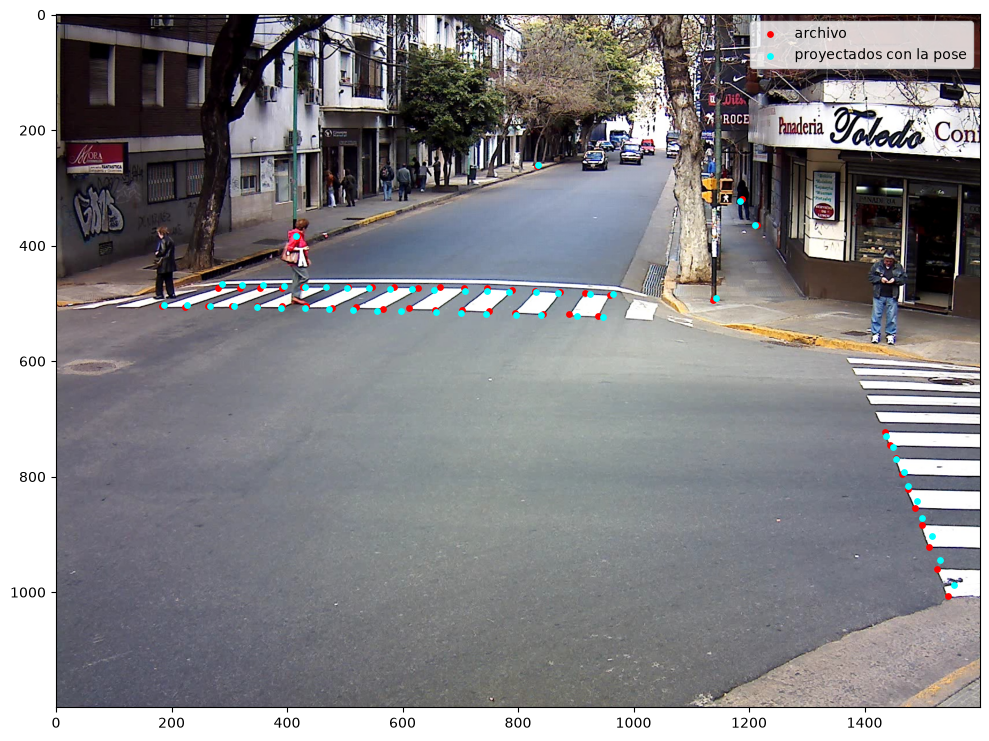

In [38]:
# PENDIENTE (Ej 5b): falta la corrección de obtenerPose2D (PR #20).
# Hasta entonces, esta reproyección da lo mismo que la de H.

# Pose de la cámara en esta vista
Rj, tj = alc.obtenerPose2D(H, K_calle)
print("R:\n", Rj)
print("t:", tj)

# Reproyección de los puntos con K·[r1 r2 t]
M = alc.multiplicar(K_calle, np.hstack((Rj[:, :2], tj.reshape(3, 1))))
proy_pose = alc.multiplicar(M, P)
u_pose = proy_pose[0] / proy_pose[2]
v_pose = proy_pose[1] / proy_pose[2]

plt.figure(figsize=(12, 9))
plt.imshow(img)
plt.scatter(imgPts[:, 0], imgPts[:, 1], c="red", s=15, label="archivo")
plt.scatter(u_pose, v_pose, c="cyan", s=15, label="proyectados con la pose")
plt.legend()
plt.show()

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

In [32]:
def pixeles_a_mundo(H_inv, pixeles):
    """
    Lleva píxeles de la imagen a coordenadas del plano de la calle.

    Parámetros
    ----------
    H_inv : ndarray (3, 3) — inversa de la homografía calle → imagen.
    pixeles : ndarray (n, 2) — puntos (u, v) en píxeles, sobre el piso.

    Devuelve
    --------
    mundo : ndarray (n, 2) — puntos (X, Y) en metros.
    """

    #Armo los pixeles en coord homogeneas
    P = np.vstack((pixeles[:, 0], pixeles[:, 1], np.ones(pixeles.shape[0])))

    proy = alc.multiplicar(H_inv, P)

    x = proy[0] / proy[2]
    y = proy[1] / proy[2]

    return alc.transponer(np.vstack((x,y)))

def name2sec(foto):
    """
    Convierte el nombre de una captura en segundos desde las 00:00.

    Parámetros
    ----------
    foto : str — instante de la captura como "hora_minuto_segundo_milisegundo".

    Devuelve
    --------
    segundos : float — instante de la captura, en segundos.
    """
    hora,minuto,segundo,ms = foto.split("_")
    return 3600*int(hora) + 60*int(minuto) + int(segundo) + int(ms)/1000 

    

señora : velocidad media 1.3778292334715156 m/s = 4.960185240497457 km/h
taxi : velocidad media 13.511853929563012 m/s = 48.64267414642684 km/h
camioneta : velocidad media 14.178941330105351 m/s = 51.044188788379266 km/h


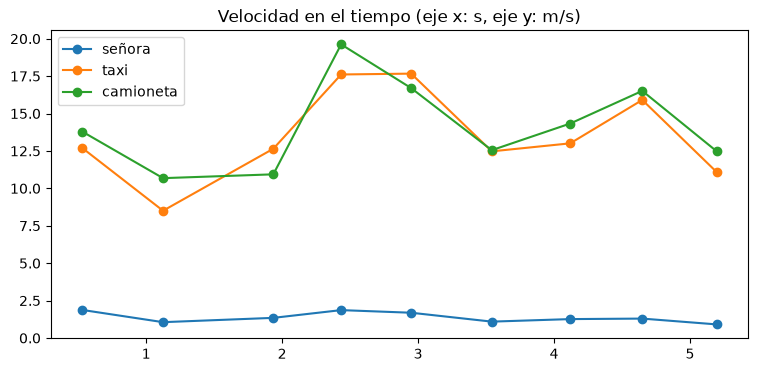

In [35]:
def calcular_velocidad(archivo_marcas, H_inv):
    """
    Calcula la velocidad de un agente a partir de sus marcas en la imagen.

    Parámetros
    ----------
    archivo_marcas : str — nombre del .csv en salguero/ (columnas captura;u;v).
    H_inv : ndarray (3, 3) — inversa de la homografía calle → imagen.

    Devuelve
    --------
    t : ndarray (n,) — tiempo de cada marca, en segundos desde la primera.
    v : ndarray (n-1,) — velocidad en cada tramo, en m/s.
    mundo : ndarray (n, 2) — posiciones (X, Y) en metros.
    """
    marcas = pd.read_csv(os.path.join("salguero", archivo_marcas), sep=";", dtype={"captura": str})
    n = marcas.shape[0]

    # Tiempo de cada captura, en segundos desde la primera
    t = np.zeros(n)
    for i in range(n):
        t[i] = name2sec(marcas["captura"][i])
    t = t - t[0]

    # Paso los píxeles a metros sobre el plano de la calle
    pixeles = np.vstack((marcas["u"].values, marcas["v"].values)).T
    mundo = pixeles_a_mundo(H_inv, pixeles)

    # Distancia recorrida entre marcas consecutivas
    dX = np.diff(mundo[:, 0])
    dY = np.diff(mundo[:, 1])
    dist = np.sqrt(dX**2 + dY**2)

    # Velocidad = distancia / tiempo entre marcas
    v = dist / np.diff(t)

    return t, v, mundo


H_inv = alc.inversa(H)
agentes = [("señora", "marcas_senora.csv"),
           ("taxi", "marcas_taxi.csv"),
           ("camioneta", "marcas_camioneta.csv")]

plt.figure(figsize=(9, 4))
for nombre, archivo in agentes:
    t, v, mundo = calcular_velocidad(archivo, H_inv)
    print(nombre, ": velocidad media", np.mean(v), "m/s =", 3.6*np.mean(v), "km/h")
    plt.plot(t[1:], v, marker="o", label=nombre)

plt.title("Velocidad en el tiempo (eje x: s, eje y: m/s)")
plt.legend()
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---